# NuFANCI proteomics: clustering of NuFANCI and input samples

Z-scored, centred protein intensities of all NuFANCI and input samples (nucleoli: HCT116, HepG2, human liver NPM1 sorts; speckles: HCT116 SRRM2 sort; NUP98-DDX10 sort) are clustered (Ward, Euclidean) and annotated with published nucleolar and speckle protein lists. Writes the clustered heatmap, dendrogram and cluster assignments.

**Inputs** (in the working directory): `combined_protein_f.tsv`, `experiment_annotation.tsv` and the FragPipe-Analyst output matrices (`*_minImputation.*`), all available from the public repository; published marker lists in `reference_lists/` (see the module README).

Original notebook: `FANCY_CoOmics_20260520.ipynb`.

In [43]:
from __future__ import print_function
import sys
import os
import pandas as pd
import csv
import seaborn as sns
import time
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import warnings
import numpy as np
import plotly
import plotly.express as px
import plotly.graph_objects as go
from functools import reduce
import scipy
from scipy.spatial import distance
from scipy.cluster import hierarchy
import sklearn
from sklearn.metrics import silhouette_score
from sklearn import cluster, datasets, mixture
from sklearn.neighbors import kneighbors_graph
from string import ascii_letters
from scipy.stats import zscore

np.random.seed(12345)
import matplotlib.pyplot as plt


warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl") # remove warning from mac
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+notebook" 
from IPython.display import display, HTML, Markdown
display(HTML("<style>:root { --jp-notebook-max-width: 80% !important; }</style>"))
from sklearn.utils._openmp_helpers import _openmp_effective_n_threads, _openmp_parallelism_enabled
_openmp_effective_n_threads(6)

plt.rcParams['pdf.fonttype'] = 42
import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'

os.environ.setdefault("TF_NUM_THREADS", "10")
os.environ.setdefault("TF_LOOP_PARALLEL_ITERATIONS", "10")

'10'

In [2]:
colorway=["#B80000", "#E81E63", "#8D239E", "#673AB7", "#3F51B5", "#253985", "#02A8F4", "#009688", "#8BC34A", "#FF9800", "#FE5622", "#795648", "#9E9E9E", "#617D8B",]

plotly.io.templates["alphastats_colors"] = plotly.graph_objects.layout.Template(
    layout=plotly.graph_objects.Layout(
        paper_bgcolor="rgba(0,0,0,0)",
        plot_bgcolor="rgba(0,0,0,0)",
        colorway=colorway
        ,
    )
)
plotly.io.templates.default = "simple_white+alphastats_colors"

display(Markdown('<br>'.join(
    f'<span style="font-family: monospace">{color} <span style="color: {color}">████████</span></span>'
    for color in colorway
)))
len(colorway)

<span style="font-family: monospace">#B80000 <span style="color: #B80000">████████</span></span><br><span style="font-family: monospace">#E81E63 <span style="color: #E81E63">████████</span></span><br><span style="font-family: monospace">#8D239E <span style="color: #8D239E">████████</span></span><br><span style="font-family: monospace">#673AB7 <span style="color: #673AB7">████████</span></span><br><span style="font-family: monospace">#3F51B5 <span style="color: #3F51B5">████████</span></span><br><span style="font-family: monospace">#253985 <span style="color: #253985">████████</span></span><br><span style="font-family: monospace">#02A8F4 <span style="color: #02A8F4">████████</span></span><br><span style="font-family: monospace">#009688 <span style="color: #009688">████████</span></span><br><span style="font-family: monospace">#8BC34A <span style="color: #8BC34A">████████</span></span><br><span style="font-family: monospace">#FF9800 <span style="color: #FF9800">████████</span></span><br><span style="font-family: monospace">#FE5622 <span style="color: #FE5622">████████</span></span><br><span style="font-family: monospace">#795648 <span style="color: #795648">████████</span></span><br><span style="font-family: monospace">#9E9E9E <span style="color: #9E9E9E">████████</span></span><br><span style="font-family: monospace">#617D8B <span style="color: #617D8B">████████</span></span>

14

In [74]:
experiment_annotation = pd.read_csv('./experiment_annotation.tsv', sep = '\t')
experiment_annotation = experiment_annotation.set_index('sample')

In [67]:
combined_protein = pd.read_csv("combined_protein_f.tsv", low_memory=False, sep = "\t")
combined_protein = combined_protein.set_index('Protein ID')

In [68]:
Andersen2005 = pd.read_csv('reference_lists/NucleolusList/Andersen2005_idmapping_active_true_2024_08_28.tsv',low_memory=False, sep = '\t')
SubCellBarcode = pd.read_csv('reference_lists/NucleolusList/SubCell_markerProteins_annotated.csv',low_memory=False)
Stenstrom2020 = pd.read_excel('reference_lists/NucleolusList/msb209469-sup-0002-datasetev1.xlsx', sheet_name=1)
Stenstrom2020 = Stenstrom2020[~Stenstrom2020['Uniprot ID'].isna()]
Zhang2025 = pd.read_csv('reference_lists/NucleolusList/Zang2025.csv',low_memory=False)
Dyakov_df = pd.read_excel("reference_lists/Speackle_lists_media-1.xlsx", sheet_name= "1. All term lists")
#Dyakov_df.info()
Dyakov_Paraspeckle_l = Dyakov_df['Paraspeckle curated'].tolist()
GO_nukl_spk_l = Dyakov_df['GO:CC Nuclear speck (GO:0016607)'].tolist()
Dyakov_nukl_spk_l = Dyakov_df['Nuclear speckle curated'].tolist()
Dyakov_CajalBody_l = Dyakov_df['Cajal body curated'].tolist()
Dyakov_HistoneBody_l = Dyakov_df['Histone locus body curated + putative'].tolist()
Dyakov_PML_body_l = Dyakov_df['PML body curated'].tolist()
Dyakov_Polycomb_l = Dyakov_df['Polycomb body curated'].tolist()
Dyakov_NuclearStress_l = Dyakov_df['Nuclear stress body (nSB) curated'].tolist()
Dyakov_Perinucleolar_l = Dyakov_df['Perinucleolar compartment (PNC) curated'].tolist()

Dopie_df = pd.read_excel("reference_lists/Dopie_etall_2020_jcb_201910207_tables1.xlsx", sheet_name= "Speckle ratio(Top 400)")
Dopie_df_l = Dopie_df['Gene names'].tolist()

In [5]:
# cluster_matrix = pd.read_csv('cluster_matrix.tsv'
#                              ,low_memory=False, sep = '\t')

cluster_matrix = pd.read_csv('Imputed_matrix_minImputation.csv',low_memory=False)
cluster_matrix.columns = [i.replace(" MaxLFQ.Intensity_imputed_intensity", "") for i in cluster_matrix.columns]
cluster_matrix = cluster_matrix.set_index('ProteinID')
cluster_matrix.tail()
print(cluster_matrix.shape)

(7059, 38)


In [60]:
cm = pd.read_csv('cluster_matrix_minImputation.tsv',low_memory=False, sep = '\t')
cm.columns = [i.replace(" MaxLFQ.Intensity", "") for i in cm.columns]
cm = cm.set_index('ProteinID')
cm.shape

(6660, 38)

In [62]:
center_function = lambda x: x - x.mean()
zscore_safe = lambda x: (x - x.mean()) / (x.std() + 1e-12)

groups = ["NUCL_HCT116_NPM1_FANCI_1", "NUCL_HCT116_NPM1_FANCI_2", "NUCL_HCT116_NPM1_FANCI_3",
"NUCL_HepG2_NPM1_FANCI_1", "NUCL_HepG2_NPM1_FANCI_3", "NUCL_HepG2_NPM1_FANCI_4",
"NUCL_HSLiver_NPM1_FANCI_1", "NUCL_HSLiver_NPM1_FANCI_2", "NUCL_HSLiver_NPM1_FANCI_4", "NUCL_HSLiver_NPM1_FANCI_6", "NUCL_HSLiver_NPM1_FANCI_7",
"NUCL_HCT116_SRRM2_FANCI_1", "NUCL_HCT116_SRRM2_FANCI_2", "NUCL_HCT116_SRRM2_FANCI_3",
 "NOP98_DX10_FANCI_1", "NOP98_DX10_FANCI_2", "NOP98_DX10_FANCI_3", "NOP98_DX10_FANCI_4",
    
    
    "NUCL_HCT116_NPM1_Input_1", "NUCL_HCT116_NPM1_Input_2", "NUCL_HCT116_NPM1_Input_3", 
"NUCL_HepG2_NPM1_Input_1", "NUCL_HepG2_NPM1_Input_3", "NUCL_HepG2_NPM1_Input_4", 
"NUCL_HSLiver_NPM1_Input_1", "NUCL_HSLiver_NPM1_Input_2", "NUCL_HSLiver_NPM1_Input_4", "NUCL_HSLiver_NPM1_Input_6", "NUCL_HSLiver_NPM1_Input_7",
"NUCL_HCT116_SRRM2_Input_1", "NUCL_HCT116_SRRM2_Input_2", "NUCL_HCT116_SRRM2_Input_3", 
 "NOP98_HCT116_Input_1", "NOP98_HCT116_Input_2", "NOP98_HCT116_Input_3", "NOP98_HCT116_Input_4",


]
print(cluster_matrix.shape)
cluster_matrix_f = cluster_matrix.loc[cm.index, groups]
# cluster_matrix_f = cluster_matrix.loc[:, groups]
data_centered = center_function(cluster_matrix_f.T)
data_centered = data_centered.T

data_zscore = zscore_safe(cluster_matrix_f.T)
data_zscore = data_zscore.T

print(data_centered.shape)

(7059, 38)
(6660, 36)


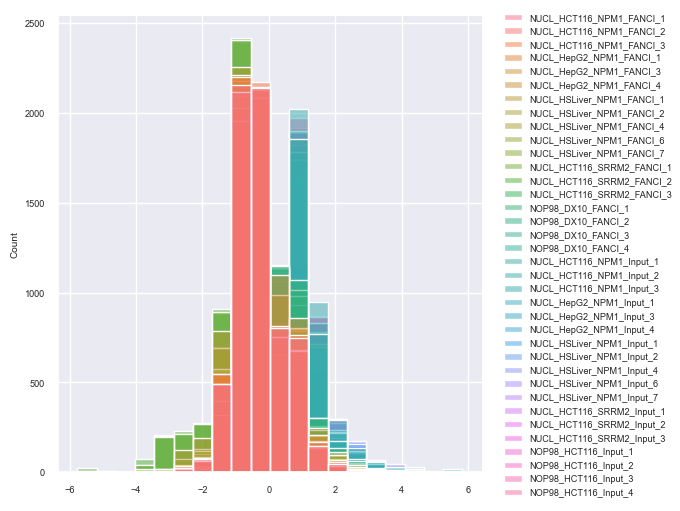

In [63]:
sns.displot(data_zscore, bins=20)

In [69]:
annot = ["Entry Name", "Gene", "Protein Length", "Organism", "Protein Existence", "Description"]
Hsapiens_Uniprot_annotation = combined_protein.loc[:, annot]
df = pd.merge(data_zscore, Hsapiens_Uniprot_annotation, how="left", left_index=True, right_index=True)

In [70]:
df['Andersen2005'] = df.index.to_series().apply(lambda x: any(i in x for i in Andersen2005['Entry']))
df['SubCellBarcode'] = df.index.to_series().apply(lambda x: any(i in x for i in SubCellBarcode[SubCellBarcode['Compartments']=="N3"]['ProteinID']))
df['SubCellBarcode_N'] = df.index.to_series().apply(lambda x: any(i in x for i in SubCellBarcode[SubCellBarcode['Compartments'].isin(['N1','N2','N3', 'N4'])]['ProteinID']))
df['Stenstrom2020'] = df.index.to_series().apply(lambda x: any(i in x for i in set(Stenstrom2020['Uniprot ID'])))
df['Zhang2025'] = df.index.to_series().apply(lambda x: any(i in x for i in set(Zhang2025['ProteinID'])))

df['Dyakov_Paraspeckle'] = df['Gene'].astype(str).apply(lambda x: any(i in x for i in Dyakov_df['Paraspeckle curated'].astype(str)))
df['Dyakov_nukl_spk'] = df['Gene'].astype(str).apply(lambda x: any(i in x for i in Dyakov_df['Nuclear speckle curated'].astype(str)))
df['Dopie_Top400'] = df['Gene'].astype(str).apply(lambda x: any(i in x for i in Dopie_df['Gene names'].astype(str)))

In [71]:
print(df.Andersen2005.value_counts())
print(df.SubCellBarcode.value_counts())
print(df.Stenstrom2020.value_counts())
print(df.SubCellBarcode_N.value_counts())

print(df.Zhang2025.value_counts())
print(df.Dyakov_Paraspeckle.value_counts())
print(df.Dyakov_nukl_spk.value_counts())
print(df.Dopie_Top400.value_counts())

False    6074
True      586
Name: Andersen2005, dtype: int64
False    6460
True      200
Name: SubCellBarcode, dtype: int64
False    6001
True      659
Name: Stenstrom2020, dtype: int64
False    6030
True      630
Name: SubCellBarcode_N, dtype: int64
False    5732
True      928
Name: Zhang2025, dtype: int64
False    6601
True       59
Name: Dyakov_Paraspeckle, dtype: int64
False    6486
True      174
Name: Dyakov_nukl_spk, dtype: int64
False    6216
True      444
Name: Dopie_Top400, dtype: int64


In [72]:
Anderson2005_df = df.pop("Andersen2005")
SubCellBarcode_df = df.pop("SubCellBarcode")
SubCellBarcode_N_df = df.pop("SubCellBarcode_N")
Stenstrom2020_df = df.pop("Stenstrom2020")

Zhang2025_df = df.pop("Zhang2025")
Dyakov_Paraspeckle_df = df.pop("Dyakov_Paraspeckle")
Dyakov_nukl_spk_N_df = df.pop("Dyakov_nukl_spk")
Dopie_Top400_df = df.pop("Dopie_Top400")

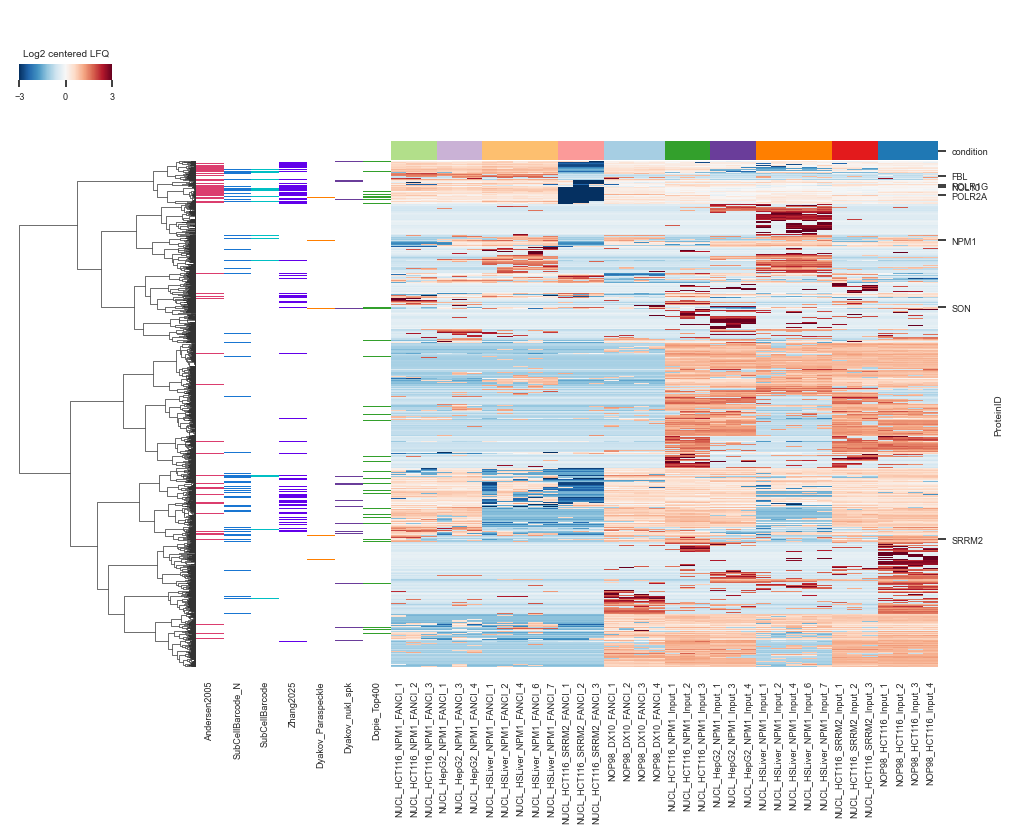

In [77]:
sns.set(font_scale=0.6)
custom_palette = sns.color_palette("RdBu_r", 11,as_cmap= True)

lut1 = dict(zip([True, False], ['#DB3D6E', '#ffffff']))
row_colors1 = Anderson2005_df.map(lut1)

lut2 = dict(zip([True, False], ['#1976D2', '#ffffff']))
row_colors2 = SubCellBarcode_N_df.map(lut2)

lut3 = dict(zip([True, False], ['#00BFC4', '#ffffff']))
row_colors3 = SubCellBarcode_df.map(lut3)

lut4 = dict(zip([ True, False], ['#6200EA', '#ffffff']))
row_colors4 = Zhang2025_df.map(lut4)

lut5 = dict(zip([True, False], ['#ff7f00', '#ffffff']))
row_colors5 = Dyakov_Paraspeckle_df.map(lut5)

lut6 = dict(zip([True, False], ['#6a3d9a', '#ffffff']))
row_colors6 = Dyakov_nukl_spk_N_df.map(lut6)

lut7 = dict(zip([True, False], ['#33a02c', '#ffffff']))
row_colors7 = Dopie_Top400_df.map(lut7)

row_colors = pd.concat([row_colors1,row_colors2,row_colors3,row_colors4,row_colors5,
                        row_colors6,row_colors7
                       ],axis=1)

# Create a color palette for the groups

unique_groups = experiment_annotation['condition'].unique()
palette = sns.color_palette("Paired", len(unique_groups))
group_colors = dict(zip(unique_groups, palette))

# Map colors to the DataFrame for column colors
col_colors = experiment_annotation['condition'].map(group_colors)

#Plot the heatmap
heat_clust = sns.clustermap(data_zscore,
                            col_cluster=False,
                            yticklabels=False,
                            method='ward',
                            cmap=custom_palette,
                             vmin=-3,
                            center= 0,
                             vmax=3,
                            metric='seuclidean',
                            row_colors=row_colors,
                            col_colors=col_colors,
                            cbar_kws=dict(
                                ticks=[-3, 0, 3],
                                orientation="horizontal",  
                            )
                           )

x0, _y0, _w, _h = heat_clust.cbar_pos
heat_clust.ax_cbar.set_position([x0,
                                 0.9,
                                 heat_clust.ax_row_dendrogram.get_position().width/2,
                                 0.02]
                               )
heat_clust.ax_cbar.set_title('Log2 centered LFQ')
heat_clust.ax_cbar.tick_params(axis='x',
                               length=5)


reordered_labels = data_centered.index[heat_clust.dendrogram_row.reordered_ind].tolist()

use_labels = [#"msfGFP",
              "P06748", # NPM1
              "P22087", # FBL 
              "P24928", # POL2A
              "O15446", # POLR1G
              "Q9BSC4", # NOL10
              "Q9UQ35", # SRRM2
              "P18583", #SOM
    
             ]

# Find where these proteins ended up after clustering
use_ticks = [reordered_labels.index(label) + .5 for label in use_labels]

# --- NEW CODE ---
# Map the ProteinIDs to their corresponding Gene Names using the annot table
gene_names = Hsapiens_Uniprot_annotation.loc[use_labels, 'Gene'].tolist()

# Apply the ticks, but pass the mapped gene_names instead of the ProteinIDs
heat_clust.ax_heatmap.set(yticks=use_ticks, yticklabels=gene_names)

heat_clust.fig.set_size_inches((10,8))

heat_clust.savefig("Heatmap_clustered_Input_FANCI_centered.pdf", format = 'pdf')
heat_clust.savefig("Heatmap_clustered_Input_FANCI_centered.png", format = 'png', dpi = 300)

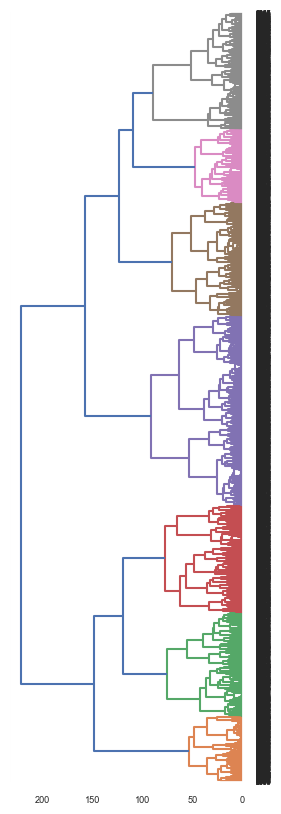

In [82]:
plt.figure(figsize=(3,10))
den = scipy.cluster.hierarchy.dendrogram(heat_clust.dendrogram_row.linkage,
                                         #labels = list(heat_clust.data2d.index),
                                         orientation='left',
                                         color_threshold = 100,
                                         get_leaves = True
                                         )
plt.savefig('den_Heatmap_clustered_NPM1_SRRM2_FANCI_Input_log_qualite.png', format='png', bbox_inches='tight')
plt.savefig('den_Heatmap_clustered_NPM1_SRRM2_FANCI_Input_log_qualite.pdf', format='pdf', bbox_inches='tight')

In [83]:
labels = heat_clust.ax_heatmap.yaxis.get_majorticklabels()
ordered_row_df_heat = heat_clust.data2d
row_order = heat_clust.data2d.index

In [84]:
#extract ivl list (order of the dendrogram), leaves_color_list (cluster)
ordered_row_df_heat.insert(0 , "cluster", den["leaves_color_list"])
ordered_row_df_heat.insert(1 ,'order', np.arange(len(data_centered)))
ordered_row_df_heat.insert(2 , "original_index", den["ivl"])
ordered_row_df_heat = ordered_row_df_heat.iloc[:,0:3]
ordered_row_df_heat.head()

ValueError: cannot insert cluster, already exists

In [85]:
ordered_row_df_heat.to_csv('FANCI_Input_ordered_row_df_heatmap_wClustering_Total.csv', index=True)

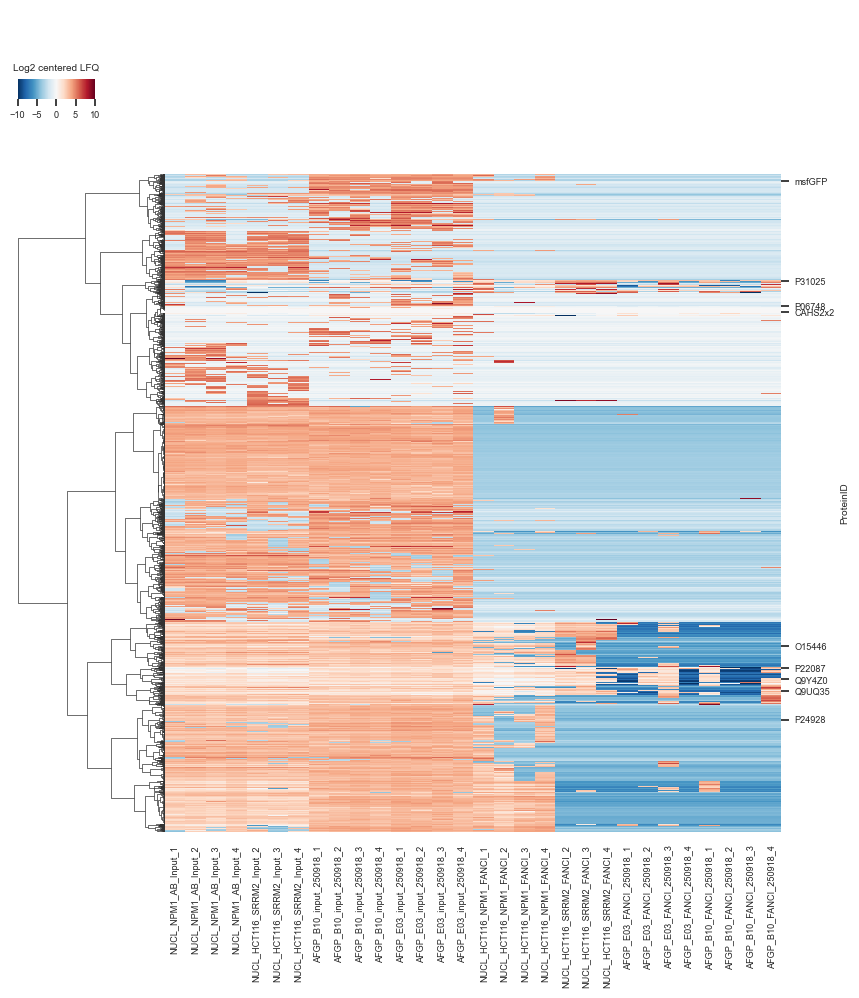

In [111]:
#Plot the reference data

sns.set(font_scale=0.6)
custom_palette = sns.color_palette("RdBu_r", 31,as_cmap= True)

#Plot the heatmap
heat_clust = sns.clustermap(cluster_E03B10_centered,
                            col_cluster=False,
                            yticklabels=False,
                            method='ward',
                            cmap=custom_palette,
                             vmin=-10,
                            center= 0,
                             vmax=10,
                            metric='euclidean',
                            cbar_kws=dict(
                                ticks=[-10, -5, 0, 5, 10],
                                orientation="horizontal",  
                            )
                           )

x0, _y0, _w, _h = heat_clust.cbar_pos
heat_clust.ax_cbar.set_position([x0,
                                 0.9,
                                 heat_clust.ax_row_dendrogram.get_position().width/2,
                                 0.02]
                               )
heat_clust.ax_cbar.set_title('Log2 centered LFQ')
heat_clust.ax_cbar.tick_params(axis='x',
                               length=5)


reordered_labels = cluster_E03B10_centered.index[heat_clust.dendrogram_row.reordered_ind].tolist()
use_labels = ["msfGFP",
              "P06748", #NPM1
              "P22087", #FBL 
              "P24928", # POL2A
              "O15446", # POLR1G
              "CAHS2x2", 
              "Q9UQ35", # SRRM2
              "Q9Y4Z0", # LSM4
              "P31025" # LCN1
             ]

use_ticks = [reordered_labels.index(label) + .5 for label in use_labels]

heat_clust.ax_heatmap.set(yticks=use_ticks, yticklabels=use_labels)

heat_clust.fig.set_size_inches((8,10))

heat_clust.savefig("Heatmap_clustered_Input_FANCI_cluster_E03B10_centered.pdf", format = 'pdf')
heat_clust.savefig("Heatmap_clustered_Input_FANCI_cluster_E03B10_centered.png", format = 'png', dpi = 300)

In [120]:
combined_protein = pd.read_csv('./combined_protein_f.tsv',low_memory=False, sep = '\t')

annot = ["Protein ID", "Entry Name", "Gene", "Protein Length", "Organism", "Protein Existence", "Description"]
## reorder df based on the new order
Hsapiens_Uniprot_annotation = combined_protein.loc[:, annot]
Hsapiens_Uniprot_annotation=Hsapiens_Uniprot_annotation.rename(columns = {'Protein ID':'ProteinID'})
Hsapiens_Uniprot_annotation = Hsapiens_Uniprot_annotation.set_index('ProteinID')

experiment_annotation = pd.read_csv('./experiment_annotation_.tsv', sep = '\t')
experiment_annotation = experiment_annotation.set_index('sample')
            



In [5]:
DE_results = pd.read_csv('DE_results.csv',low_memory=False, index_col=0)

In [13]:
# DE_results.info()

DE_groups = ["NUCL_HCT116_NPM1_FANCI_vs_NUCL_HCT116_NPM1_INPUT",
             "NUCL_HCT116_SRRM2_FANCI_vs_NUCL_HCT116_SRRM2_Input",
             "NOP98_DX10_FANCI_vs_NOP98_HCT116_Input",
             "AFGP_B10_FANCI_0528_vs_AFGP_B10_input_0528",
             "AFGP_B10_FANCI_0821_vs_AFGP_B10_input_0821",
             "AFGP_B10_FANCI_0909_vs_AFGP_B10_input_0909",
             "AFGP_B10_FANCI_0918_vs_AFGP_B10_input_0918",
             "AFGP_E03_FANCI_0918_vs_AFGP_E03_input_0918",
             "CAHS2x2_FANCI_0711_vs_CAHS2x2_input_0711",
             "CAHS2x2_FANCI_1010_vs_CAHS2x2_input_1025"
             
]

suffixes = ["_log2 fold change", "_p.adj", "_p.val" , "_significant"]

target_columns = [f"{p}{s}" for p in DE_groups for s in suffixes] + ["Gene Name"]

df_subset = DE_results[target_columns]

In [14]:
df_subset.to_csv('df_subset_.csv', index=True)

In [19]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Global Settings
plt.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'

# Define your labels of interest globally
label_genes = ["NPM1", "SRRM2", "msfGFP", "CAHS2x2", "POLR1G", "POLR1A", "FBL", "LSM4", "LCN1"]

# 2. Iterate over the prefixes
for prefix in DE_groups:
    print(f"Generating plot for: {prefix}")
    
    # --- A. Dynamic Column Names ---
    # Construct the specific column names for this iteration
    col_l2fc = f"{prefix}_log2 fold change"
    col_padj = f"{prefix}_p.adj"
    col_sig  = f"{prefix}_significant"
    
    # --- B. Data Prep ---
    # Create a working copy so we don't overwrite the main dataframe
    plot_df = df_subset.copy()

    # Top positive (Red)
    df_pos = plot_df[(plot_df[col_l2fc] >= 1) & (plot_df[col_padj] <= 0.05)]
    
    # Top negative (Blue)
    df_neg = plot_df[(plot_df[col_l2fc] <= -1) & (plot_df[col_padj] <= 0.05)]

    
    # Drop rows where data might be missing for this specific contrast
    plot_df = plot_df.dropna(subset=[col_l2fc, col_padj])

    # Calculate -log10(pvalue) using the dynamic column
    # Adding a tiny epsilon (1e-300) avoids log(0) errors if p-value is exactly 0
    plot_df['neg_log10_pvalue'] = -np.log10(plot_df[col_padj])
    
    # Standardize the Log2FC column name for the plotting section below
    plot_df['log2FoldChange'] = plot_df[col_l2fc]

    # Color logic: Red (Up), Blue (Down), Grey (NS)
    # Note: We use the dynamic column names inside the condition
    plot_df["color"] = np.where(
        (plot_df[col_padj] <= 0.05) & (plot_df['log2FoldChange'] >= 1), "red",
        np.where(
            (plot_df[col_padj] <= 0.05) & (plot_df['log2FoldChange'] <= -1), "blue",
            "grey"
        )
    )

    # --- C. Ranking & Labeling ---
    
    # Calculate ranking metric
    plot_df['ranking'] = plot_df['log2FoldChange'].abs() * plot_df['neg_log10_pvalue']
    
    n = 10 # Labels per side
    
    # Top positive (Red)
    df_top_pos = plot_df[plot_df['log2FoldChange'] > 1].nlargest(n, 'ranking')
    
    # Top negative (Blue)
    df_top_neg = plot_df[plot_df['log2FoldChange'] < -1].nlargest(n, 'ranking')
    
    # Specific genes of interest (Manual list)
    df_manual = plot_df[plot_df["Gene Name"].isin(label_genes)]
    
    # Combine all labels and drop duplicates (in case a top gene is also in the manual list)
    df_labels = pd.concat([df_top_pos, df_top_neg, df_manual]).drop_duplicates(subset=["Gene Name"])

    # --- D. Plotting ---
    
    plt.figure(figsize=(6, 8))
    
    # Main scatter plot
    ax = sns.scatterplot(
        data=plot_df, 
        x='log2FoldChange', 
        y='neg_log10_pvalue', 
        hue="color", 
        palette={"red": "#E64B35", "blue": "#4DBBD5", "grey": "lightgrey"}, # Optional: using nicer hex codes
        legend=False,
        edgecolor=None, # Removes outlines for cleaner look with many points
        s=15 # Dot size
    )

    # Add labels
    for i, row in df_labels.iterrows():
        plt.annotate(
            row['Gene Name'], 
            (row['log2FoldChange'], row['neg_log10_pvalue']),
            textcoords="offset points",
            xytext=(0,10),
            ha='center',
            fontsize=9,
            color='black',
            arrowprops=dict(arrowstyle="-", color="black", lw=0.5)
        )

    # Reference lines
    plt.axhline(y=-np.log10(0.05), color='grey', linestyle='--', linewidth=0.8)
    plt.axvline(x=1, color='grey', linestyle='--', linewidth=0.8)
    plt.axvline(x=-1, color='grey', linestyle='--', linewidth=0.8)

    # Titles and Limits
    plt.xlabel('Log2 Fold Change')
    plt.ylabel('-Log10(Adj P-value)')
    plt.title(f'Volcano Plot: {prefix}') # Dynamic Title
    plt.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)
    
    # Dynamic Y-limit: set it slightly higher than the highest point to make room for labels
    ax.set(ylim=(0, 40))
    ax.set(xlim=(-15, 15)) 

    # Add a text annotation

    
    plt.text(x=6, y=10, s=len(df_pos), fontsize=12, color='red')
    plt.text(x=-6, y=10, s=len(df_neg), fontsize=12, color='red')

    # --- E. Save and Close ---
    
    # Clean filename (remove potential invalid chars just in case)
    safe_prefix = prefix.replace(" ", "_").replace("/", "-")
    plt.savefig(f'Volcano_{safe_prefix}.pdf', bbox_inches='tight')
    
    # Crucial: Close the plot to free memory for the next iteration
    plt.close()

print("All plots generated.")

Generating plot for: NUCL_HCT116_NPM1_FANCI_vs_NUCL_HCT116_NPM1_INPUT
Generating plot for: NUCL_HCT116_SRRM2_FANCI_vs_NUCL_HCT116_SRRM2_Input
Generating plot for: NOP98_DX10_FANCI_vs_NOP98_HCT116_Input
Generating plot for: AFGP_B10_FANCI_0528_vs_AFGP_B10_input_0528
Generating plot for: AFGP_B10_FANCI_0821_vs_AFGP_B10_input_0821
Generating plot for: AFGP_B10_FANCI_0909_vs_AFGP_B10_input_0909
Generating plot for: AFGP_B10_FANCI_0918_vs_AFGP_B10_input_0918
Generating plot for: AFGP_E03_FANCI_0918_vs_AFGP_E03_input_0918
Generating plot for: CAHS2x2_FANCI_0711_vs_CAHS2x2_input_0711
Generating plot for: CAHS2x2_FANCI_1010_vs_CAHS2x2_input_1025
All plots generated.
